# Notebook 2 — What Drives the Yield Curve? PCA and Rate Regimes

**Previous:** [Notebook 1 — Data cleaning and EDA](1_data_cleaning_and_eda.ipynb) ·
**Next:** [Notebook 3 — Modeling and evaluation](3_modeling_and_evaluation.ipynb)

This notebook uses **unsupervised learning** (no target variable) to answer two supporting questions:

1. **Decomposition (PCA).** Ten maturities move every day, but Notebook 1 showed they are highly correlated. How many
   underlying "factors" really drive the curve, and do they match the textbook story of **level, slope and curvature**?
   Is that structure stable across the zero-interest-rate years?
2. **Regimes (k-means clustering).** Does the curve fall into a few distinct, recognisable **rate regimes** that line up
   with known Federal Reserve policy phases? Does the next-month direction of yields differ by regime?

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

PROCESSED_DIR = Path("../data/processed")
IMG_DIR = Path("../images")
RANDOM_STATE = 42

curve = pd.read_csv(PROCESSED_DIR / "curve_clean.csv", index_col=0, parse_dates=True)
model_df = pd.read_csv(PROCESSED_DIR / "model_dataset.csv", index_col=0, parse_dates=True)
MODEL_TENORS = pd.read_csv(PROCESSED_DIR / "model_tenors.csv")["tenor"].tolist()
MATURITY_YEARS = {"1M": 1/12, "3M": 0.25, "6M": 0.5, "1Y": 1, "2Y": 2, "3Y": 3,
                  "5Y": 5, "7Y": 7, "10Y": 10, "20Y": 20, "30Y": 30}
maturities = np.array([MATURITY_YEARS[t] for t in MODEL_TENORS])
print("Tenors used:", MODEL_TENORS)

Tenors used: ['1M', '3M', '6M', '1Y', '2Y', '3Y', '5Y', '7Y', '10Y', '20Y', '30Y']


## 1. PCA on daily yield changes

We apply PCA to **daily changes** (in basis points) rather than levels, because levels are non-stationary
(Notebook 1, ADF test). All tenors are in the same unit, so we do not rescale them: PCA on the covariance matrix keeps
the fact that some maturities genuinely move more than others.

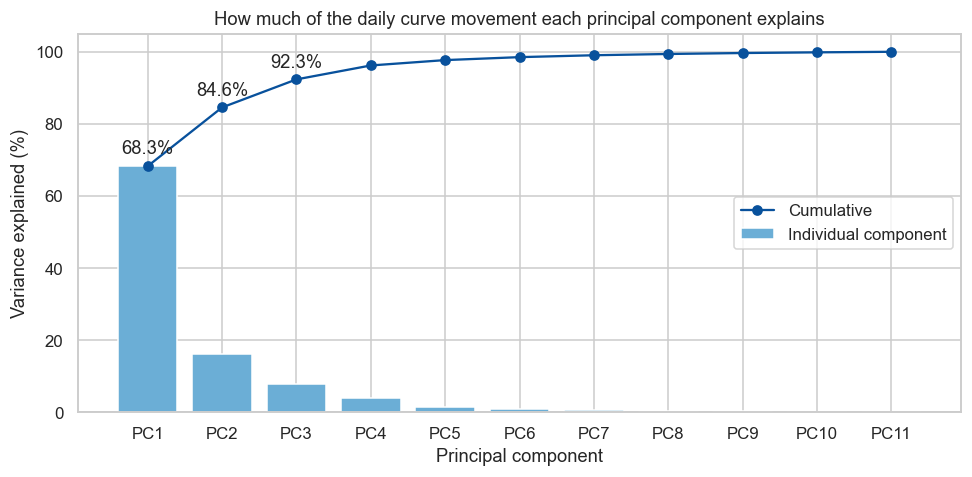

PC1    68.3
PC2    16.3
PC3     7.8
PC4     3.9


In [9]:
changes_bp = curve[MODEL_TENORS].dropna().diff().dropna() * 100

pca = PCA()
pca.fit(changes_bp)
explained = pd.Series(pca.explained_variance_ratio_ * 100, index=[f"PC{i+1}" for i in range(len(MODEL_TENORS))])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(explained.index, explained.values, color="#6baed6", label="Individual component")
ax.plot(explained.index, explained.cumsum().values, color="#08519c", marker="o", label="Cumulative")
for i, v in enumerate(explained.cumsum().values[:3]):
    ax.annotate(f"{v:.1f}%", (i, v), textcoords="offset points", xytext=(0, 8), ha="center")
ax.set_title("How much of the daily curve movement each principal component explains")
ax.set_xlabel("Principal component")
ax.set_ylabel("Variance explained (%)")
ax.set_ylim(0, 105)
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

print(explained.head(4).round(1).to_string())
#print(f"PC1: {explained.iloc[0]:.1f}%, PC2: {explained.iloc[1]:.1f}%, PC3: {explained.iloc[2]:.1f}%")


In [ ]:
'''
import pandas as pd
from sklearn.decomposition import PCA

# 1. Yields, one column per maturity (%)
yields = pd.read_csv("../data/processed/curve_clean.csv", index_col=0, parse_dates=True)
tenors = ["1M", "3M", "6M", "1Y", "2Y", "3Y", "5Y", "7Y", "10Y", "20Y", "30Y"]
yields = yields[tenors].dropna()

# 2. Daily changes in basis points
changes = yields.diff().dropna() * 100

# 3. Fit PCA
pca = PCA(n_components=3)
pca.fit(changes)

# 4. Loadings: how much each maturity moves per unit of each factor
loadings = pd.DataFrame(pca.components_.T, index=tenors, columns=["PC1", "PC2", "PC3"])

# 5. Scores: how much of each factor happened each day
scores = (changes - changes.mean()) @ loadings

# 6. Importance of each factor
explained = pca.explained_variance_ratio_

print(loadings)

'''

       PC1    PC2    PC3
1M   0.088  0.734  0.518
3M   0.103  0.448 -0.043
6M   0.135  0.297 -0.216
1Y   0.205  0.231 -0.326
2Y   0.329  0.097 -0.395
3Y   0.369  0.040 -0.301
5Y   0.403 -0.053 -0.098
7Y   0.405 -0.113  0.059
10Y  0.377 -0.149  0.188
20Y  0.337 -0.187  0.345
30Y  0.308 -0.191  0.403


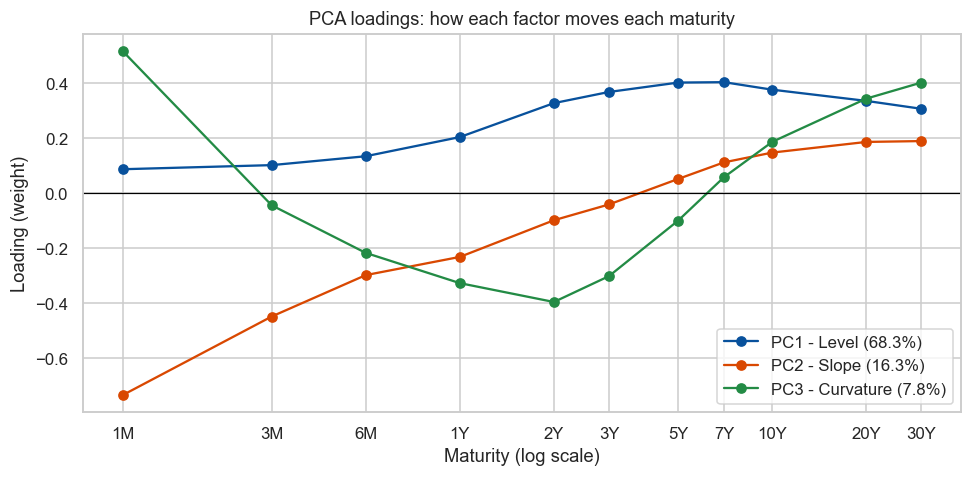

In [10]:
loadings = pd.DataFrame(pca.components_[:3].T, index=MODEL_TENORS, columns=["PC1", "PC2", "PC3"])
# PCA signs are arbitrary: orient PC1 to be positive on average and PC2 to rise with maturity, for readability
if loadings["PC1"].mean() < 0:
    loadings["PC1"] *= -1
if loadings["PC2"].iloc[-1] < loadings["PC2"].iloc[0]:
    loadings["PC2"] *= -1

fig, ax = plt.subplots(figsize=(9, 4.5))
names = {"PC1": "PC1 - Level", "PC2": "PC2 - Slope", "PC3": "PC3 - Curvature"}
for pc, colour in zip(loadings.columns, ["#08519c", "#d94801", "#238b45"]):
    ax.plot(maturities, loadings[pc], marker="o", color=colour, label=f"{names[pc]} ({explained[pc]:.1f}%)")
ax.axhline(0, color="black", lw=0.8)
ax.set_xscale("log")
ax.set_xticks(maturities)
ax.set_xticklabels(MODEL_TENORS)
ax.set_title("PCA loadings: how each factor moves each maturity")
ax.set_xlabel("Maturity (log scale)")
ax.set_ylabel("Loading (weight)")
ax.legend()
fig.tight_layout()
fig.savefig(IMG_DIR / "06_pca_loadings.png", bbox_inches="tight")
plt.show()

### Checking the level / slope / curvature interpretation with numbers, not just by eye

| Factor | Textbook shape | Quantitative check |
|---|---|---|
| PC1 — Level | All maturities move the same way | Every loading has the same sign |
| PC2 — Slope | Short and long ends move in opposite directions | Spearman rank correlation between loading and maturity close to +1 |
| PC3 — Curvature | Middle moves against the ends | Loadings change sign twice |

In [11]:
pc1_same_sign = (np.sign(loadings["PC1"]) == np.sign(loadings["PC1"].mean())).mean()
pc2_rank_corr = spearmanr(maturities, loadings["PC2"]).correlation
pc3_sign_changes = int((np.diff(np.sign(loadings["PC3"])) != 0).sum())

pd.DataFrame({
    "check": ["PC1: share of loadings with the same sign", "PC2: rank correlation with maturity",
              "PC3: number of sign changes"],
    "result": [f"{pc1_same_sign:.0%}", f"{pc2_rank_corr:.2f}", pc3_sign_changes],
})

,check,result
0,PC1: share of loadings with the same sign,100%
1,PC2: rank correlation with maturity,1.00
2,PC3: number of sign changes,2


**Interpretation.** The first three components explain the overwhelming majority of daily curve movement, and their
shapes match the textbook: **PC1 is a parallel "level" shift**, **PC2 tilts the curve (slope)**, and **PC3 bends the
middle (curvature)**. In plain words: on most days the whole curve moves up or down together, and the rest is mainly
the curve getting steeper or flatter. This confirms the pipeline is sound and justifies using a handful of
curve-shape features (level, slopes, butterfly) in the prediction model instead of all ten yields.

## 2. Is the factor structure stable? Before, during and after the zero-rate era

From December 2008 to December 2015 the Fed held its policy rate near zero. That pinned short-term yields in place,
so we expect the factors to look different in that period.

In [12]:
periods = {"Before zero rates (2001-2008)": ("2001-08-01", "2008-12-15"),
           "Zero-rate era (2008-2015)": ("2008-12-16", "2015-12-16"),
           "After (2015-today)": ("2015-12-17", str(changes_bp.index.max().date()))}

period_rows, period_loadings = [], {}
for label, (start, end) in periods.items():
    sub = changes_bp.loc[start:end]
    sub_pca = PCA(n_components=3).fit(sub)
    ratios = sub_pca.explained_variance_ratio_ * 100
    period_rows.append({"period": label, "days": len(sub), "PC1 %": ratios[0], "PC2 %": ratios[1],
                        "PC3 %": ratios[2], "top 3 %": ratios.sum(),
                        "3M daily std (bp)": sub["3M"].std(), "10Y daily std (bp)": sub["10Y"].std()})
    pc1 = sub_pca.components_[0]
    period_loadings[label] = pc1 if pc1.mean() > 0 else -pc1

stability = pd.DataFrame(period_rows).set_index("period").round(1)
stability

,days,PC1 %,PC2 %,PC3 %,top 3 %,3M daily std (bp),10Y daily std (bp)
period,,,,,,,
Before zero rates (2001-2008),1842,64.1,23.2,6.0,93.4,7.0,6.3
Zero-rate era (2008-2015),1753,85.9,7.8,1.9,95.6,1.2,6.0
After (2015-today),2703,72.6,10.6,9.0,92.3,3.0,5.3


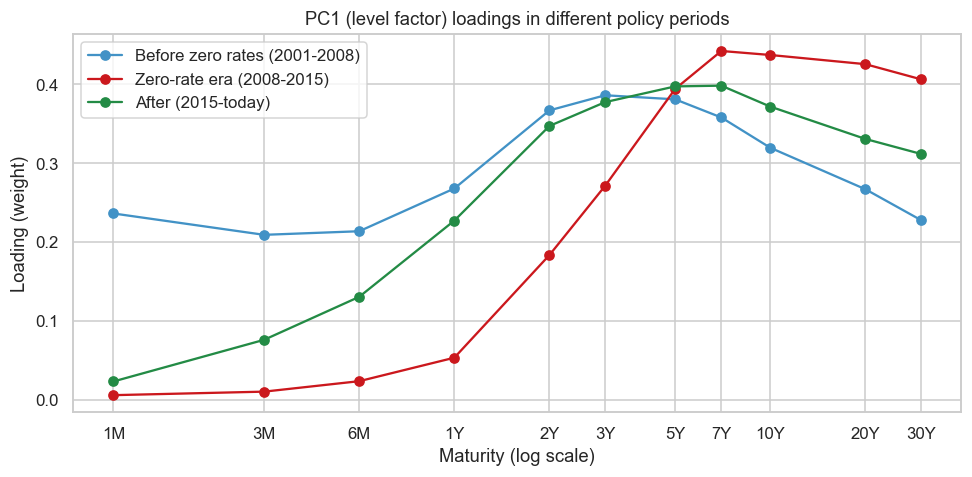

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for (label, pc1), colour in zip(period_loadings.items(), ["#4292c6", "#cb181d", "#238b45"]):
    ax.plot(maturities, pc1, marker="o", label=label, color=colour)
ax.set_xscale("log")
ax.set_xticks(maturities)
ax.set_xticklabels(MODEL_TENORS)
ax.set_title("PC1 (level factor) loadings in different policy periods")
ax.set_xlabel("Maturity (log scale)")
ax.set_ylabel("Loading (weight)")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation.** During the zero-rate era the 3-month yield barely moved (daily volatility fell from 7 bp to about
1 bp), so the level factor's weight on short maturities collapsed to almost zero and the factor became a "long-end"
factor. Because nearly all remaining movement came from long maturities moving together, PC1's share actually *rose*
to about 86% and the slope factor shrank. Since 2015 short rates move again, but the front end still carries less
weight than before 2008. **The curve's behaviour depends on the policy regime** — a model fitted on one period may not describe
another, which is one reason Notebook 3 tests models strictly forward in time.

## 3. Rate regimes with k-means clustering

To describe *where* the curve is (not how it moved today) we run PCA on yield **levels**, keep the first three scores
(level, slope, curvature of the curve on each day), standardise them, and cluster the days with **k-means**.

**Choosing k.** We use two complementary diagnostics: the **elbow method** (inertia — how tight the clusters are) and
the **silhouette score** (how well separated they are; higher is better).

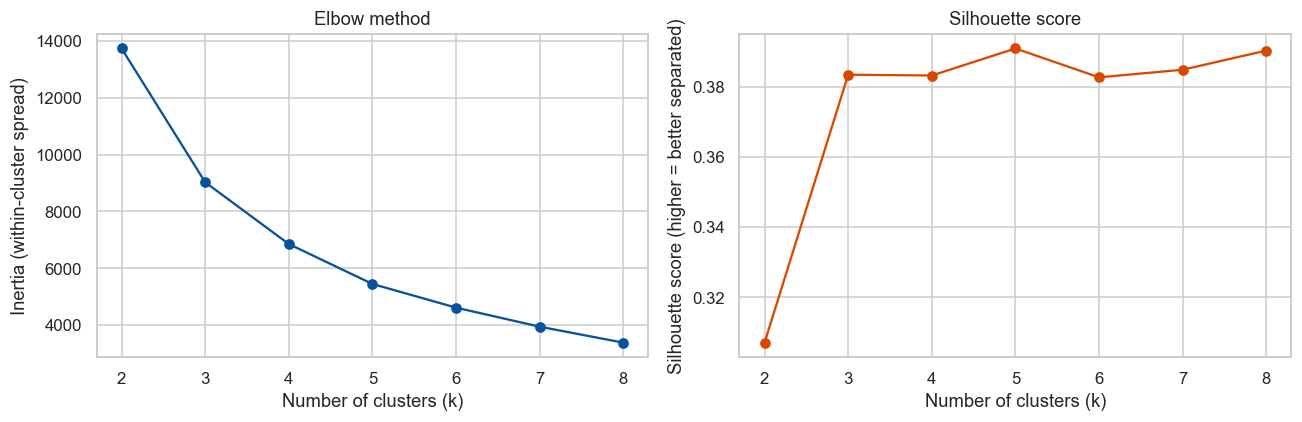

Chosen number of regimes: k = 5 (silhouette 0.39)


In [14]:
levels = curve[MODEL_TENORS].dropna()
level_pca = PCA(n_components=3).fit(levels)
scores = pd.DataFrame(level_pca.transform(levels), index=levels.index, columns=["level", "slope", "curvature"])
scores_std = StandardScaler().fit_transform(scores)

k_range = range(2, 9)
inertias, silhouettes = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(scores_std)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(scores_std, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_range), inertias, marker="o", color="#08519c")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster spread)")
axes[1].plot(list(k_range), silhouettes, marker="o", color="#d94801")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score (higher = better separated)")
fig.tight_layout()
plt.show()

# Pick the best-separated k between 3 and 6 (2 clusters is too coarse to be useful for regimes)
candidates = {k: s for k, s in zip(k_range, silhouettes) if 3 <= k <= 6}
BEST_K = max(candidates, key=candidates.get)
print(f"Chosen number of regimes: k = {BEST_K} (silhouette {candidates[BEST_K]:.2f})")

### Robustness: does the initialisation method matter?

k-means can land in different solutions depending on where it starts. We compare the smart `k-means++` start with
purely random starts across 10 seeds (one initialisation each, to expose the variability).

In [15]:
init_rows = []
for init in ["k-means++", "random"]:
    runs = [KMeans(n_clusters=BEST_K, init=init, n_init=1, random_state=seed).fit(scores_std).inertia_
            for seed in range(10)]
    init_rows.append({"initialisation": init, "mean inertia": np.mean(runs), "std of inertia": np.std(runs),
                      "best inertia": np.min(runs)})
pd.DataFrame(init_rows).round(1)

,initialisation,mean inertia,std of inertia,best inertia
0,k-means++,5476.5,89.0,5446.8
1,random,5566.8,147.4,5446.8


`k-means++` gives equal or lower inertia with less variation between runs, so the final model uses `k-means++`
with 10 restarts.

In [16]:
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE).fit(scores_std)
regimes = pd.Series(kmeans.labels_, index=scores.index, name="regime")

# Describe each regime in market terms, then name it by its average 10Y yield and slope
profile = pd.DataFrame({
    "avg 10Y yield (%)": curve.loc[regimes.index, "10Y"].groupby(regimes).mean(),
    "avg fed funds (%)": curve.loc[regimes.index, "fed_funds"].groupby(regimes).mean(),
    "avg slope 10Y-3M (bp)": ((curve["10Y"] - curve["3M"]).loc[regimes.index] * 100).groupby(regimes).mean(),
    "share of days": regimes.value_counts(normalize=True).sort_index(),
    "first seen": pd.Series({r: regimes[regimes == r].index.min().date() for r in range(BEST_K)}),
    "last seen": pd.Series({r: regimes[regimes == r].index.max().date() for r in range(BEST_K)}),
})

def describe(row):
    level = "Low" if row["avg 10Y yield (%)"] < 2.5 else ("Mid" if row["avg 10Y yield (%)"] < 4 else "High")
    slope = row["avg slope 10Y-3M (bp)"]
    shape = "inverted" if slope < 0 else ("flat" if slope < 100 else "steep")
    return f"{level} rates, {shape} curve"

profile.insert(0, "regime name", profile.apply(describe, axis=1))
# make names unique if two clusters get the same description
dupes = profile["regime name"].duplicated(keep=False)
profile.loc[dupes, "regime name"] += " (" + profile.index[dupes].astype(str) + ")"
regime_names = profile["regime name"].to_dict()
profile.round(2)

,regime name,avg 10Y yield (%),avg fed funds (%),avg slope 10Y-3M (bp),share of days,first seen,last seen
0,"Mid rates, steep curve",2.58,0.33,234.09,0.19,2002-09-05,2014-09-17
1,"High rates, inverted curve",4.36,4.72,-30.69,0.22,2006-01-03,2026-10-08
2,"Mid rates, flat curve",3.56,2.52,88.39,0.13,2005-01-14,2026-10-06
3,"Low rates, steep curve",1.84,0.64,124.69,0.26,2008-12-01,2022-01-25
4,"High rates, steep curve",4.13,1.23,298.80,0.20,2001-08-01,2026-10-07


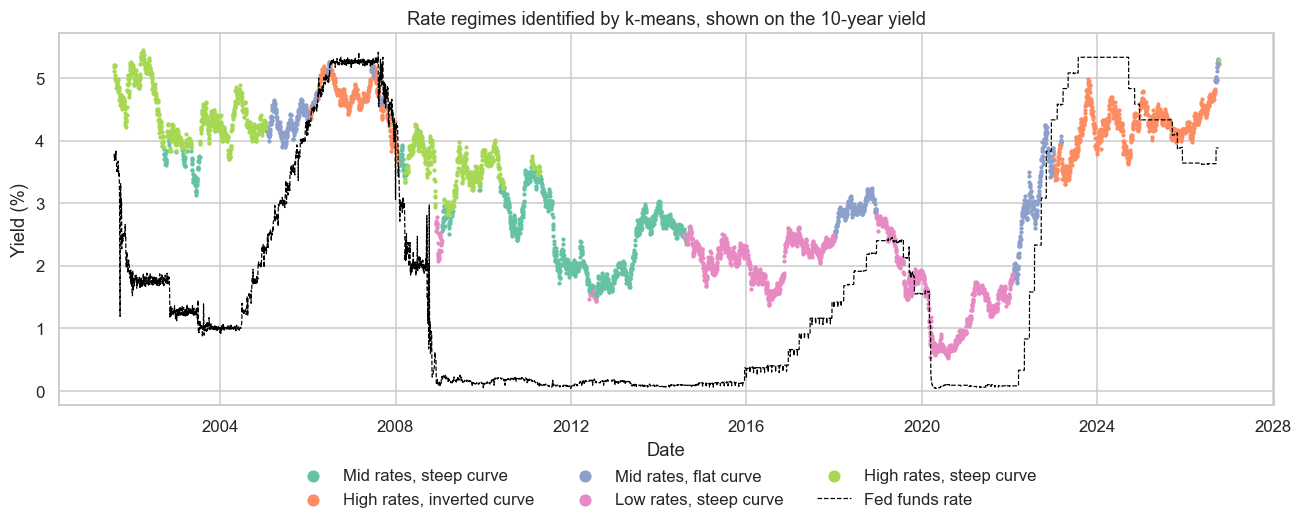

In [17]:
fig, ax = plt.subplots(figsize=(12, 5))
palette = sns.color_palette("Set2", BEST_K)
for r in range(BEST_K):
    mask = regimes == r
    ax.scatter(regimes.index[mask], curve.loc[regimes.index[mask], "10Y"], s=3, color=palette[r],
               label=regime_names[r])
ax.plot(curve.index, curve["fed_funds"], color="black", lw=0.8, ls="--", label="Fed funds rate")
ax.set_title("Rate regimes identified by k-means, shown on the 10-year yield")
ax.set_xlabel("Date")
ax.set_ylabel("Yield (%)")
ax.legend(markerscale=4, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=False)
fig.tight_layout()
fig.savefig(IMG_DIR / "07_rate_regimes.png", bbox_inches="tight")
plt.show()

### Does the next-month direction of yields differ by regime?

We join the regime labels to the modeling dataset and look at how often the 10-year rose over the following month in
each regime.

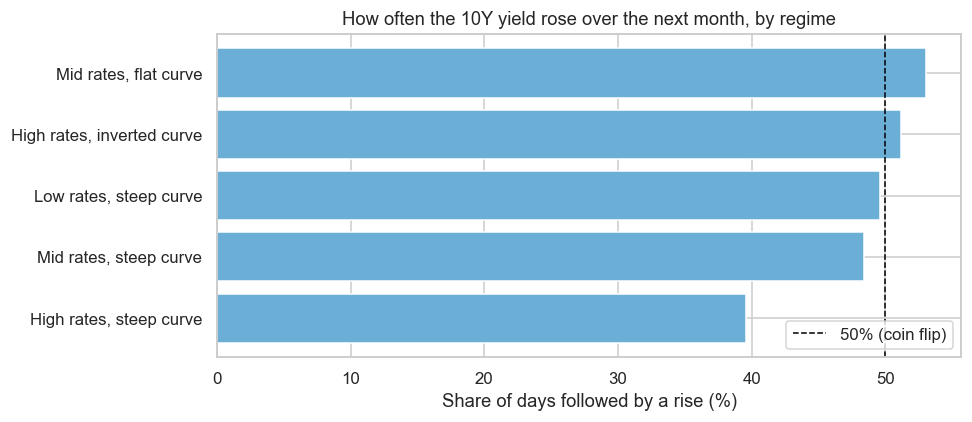

,days,share_followed_by_rise,avg_next_month_change_bp
regime name,,,
"High rates, inverted curve",1310,51.1,1.2
"High rates, steep curve",488,39.5,-7.6
"Low rates, steep curve",1652,49.6,-0.3
"Mid rates, flat curve",543,53.0,5.9
"Mid rates, steep curve",1122,48.4,0.1


In [18]:
joined = model_df.join(regimes.map(regime_names).rename("regime name"), how="inner")
by_regime = joined.groupby("regime name").agg(days=("target_up", "size"),
                                              share_followed_by_rise=("target_up", "mean"),
                                              avg_next_month_change_bp=("fwd_chg_10y_bp", "mean"))
by_regime["share_followed_by_rise"] *= 100

fig, ax = plt.subplots(figsize=(9, 4))
ordered = by_regime.sort_values("share_followed_by_rise")
ax.barh(ordered.index, ordered["share_followed_by_rise"], color="#6baed6")
ax.axvline(50, color="black", ls="--", lw=1, label="50% (coin flip)")
ax.set_title("How often the 10Y yield rose over the next month, by regime")
ax.set_xlabel("Share of days followed by a rise (%)")
ax.set_ylabel("")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
by_regime.round(1)

**Interpretation.** The clusters line up with recognisable chapters of Fed history:

- *High rates, steep curve* — the early 2000s and the 2008–2011 crisis response, when the Fed had cut but long yields stayed high;
- *Mid rates, flat curve* — the late stages of tightening cycles (2005, 2018, 2022);
- *High rates, inverted curve* — 2006–07 and the post-2023 period of restrictive policy;
- *Mid* and *Low rates, steep curve* — the zero-rate and low-rate years of 2010–2021.

The odds of a rise differ by regime: in the *high rates, steep curve* regime only about 40% of days were followed by a
rise (average next-month change about −8 bp), while in the *mid rates, flat curve* regime it was about 53% (+6 bp).
So the **curve state carries some information about what comes next**, though the differences are modest. The
silhouette score (about 0.4) is moderate, which is expected: real regime changes are gradual, not sharp breaks.

**Why regimes are *not* used as a model feature.** The clusters were fitted on the full history, including the test
period. Feeding them into the classifier would leak future information. Notebook 3 instead uses the raw curve-shape
features (level, slope, curvature), which are computed day by day.

## Summary of Notebook 2

- **Three factors — level, slope, curvature — explain almost all daily movement** in ten Treasury maturities.
- The structure **shifts across policy regimes**: in the zero-rate era short maturities stopped moving.
- k-means finds a small number of interpretable **rate regimes**, and the odds of a rising yield differ between them.

**Next:** [Notebook 3 — Modeling and evaluation](3_modeling_and_evaluation.ipynb)